## *Experiment 04: Hierarchical Two-Stage Joint Autoencoder-MLP for FiveDataset*

### Ý tưởng
Bài toán khó nhất vẫn là cụm:
- `AML`
- `CML`
- `MDS`

Vì vậy notebook này vẫn dùng **2 stage**:

#### - Stage 1
Phân loại 4 nhóm:
- `ALL`
- `CLL`
- `Healthy`
- `Myeloid`

Trong đó:
- `Myeloid = AML + CML + MDS`

#### - Stage 2
Chỉ xử lý nhóm `Myeloid`, nhưng thay vì:
- chỉ dùng MLP thuần
- hoặc chỉ dùng Autoencoder rồi classifier tách rời

thì ở đây dùng cách:

1. **Pretrain Denoising Autoencoder**
2. **Fine-tune encoder + decoder + classifier cùng lúc**

Loss của Stage 2 khi fine-tune:
- `classification loss`
- cộng với một phần nhỏ `reconstruction loss`

### Mục tiêu
- giữ được latent representation ổn định
- nhưng vẫn buộc encoder học đặc trưng có ích cho phân loại
- tăng cơ hội vượt ex03


### Bước 1. Import thư viện và khởi tạo thư mục output

In [1]:

import os
import re
import copy
import random
import zipfile
import warnings
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

from sklearn.feature_selection import SelectKBest, f_classif
from sklearn.metrics import (
    accuracy_score,
    classification_report,
    confusion_matrix,
    ConfusionMatrixDisplay,
    f1_score,
    precision_score,
    recall_score,
    roc_auc_score
)
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import LabelEncoder, StandardScaler, label_binarize

import torch
import torch.nn as nn
from torch.utils.data import Dataset, DataLoader, WeightedRandomSampler

warnings.filterwarnings("ignore")

def seed_everything(seed=42):
    random.seed(seed)
    np.random.seed(seed)
    torch.manual_seed(seed)
    torch.cuda.manual_seed_all(seed)

def get_next_run_dir(model_root: Path) -> Path:
    model_root.mkdir(parents=True, exist_ok=True)
    pattern = re.compile(r"run(\d+)$")
    nums = []
    for p in model_root.iterdir():
        if p.is_dir():
            m = pattern.match(p.name)
            if m:
                nums.append(int(m.group(1)))
    next_num = 1 if not nums else max(nums) + 1
    return model_root / f"run{next_num:02d}"

def load_five_dataset(data_dir: Path, class_col: str = "Class") -> pd.DataFrame:
    csv_path = data_dir / "FiveDataset.csv"
    zip_path = data_dir / "FiveDataset.zip"

    if csv_path.exists():
        df = pd.read_csv(csv_path)
    elif zip_path.exists():
        with zipfile.ZipFile(zip_path, "r") as zf:
            target = None
            for name in zf.namelist():
                if name.lower().endswith(".csv") and "fivedataset" in name.lower():
                    target = name
                    break
            if target is None:
                candidates = [n for n in zf.namelist() if n.lower().endswith(".csv")]
                if not candidates:
                    raise FileNotFoundError("Không tìm thấy file CSV trong FiveDataset.zip")
                target = candidates[0]
            with zf.open(target) as f:
                df = pd.read_csv(f)
    else:
        raise FileNotFoundError("Không tìm thấy FiveDataset.csv hoặc FiveDataset.zip trong data/raw")

    if class_col not in df.columns:
        raise ValueError(f"Không tìm thấy cột nhãn '{class_col}'")
    return df

seed_everything(42)

PROJECT_ROOT = Path.cwd()
if PROJECT_ROOT.name == "notebooks":
    PROJECT_ROOT = PROJECT_ROOT.parent

DATA_DIR = PROJECT_ROOT / "data" / "raw"
EXPERIMENT_ROOT = PROJECT_ROOT / "outputs" / "ex04"
RUN_DIR = get_next_run_dir(EXPERIMENT_ROOT)

FIG_DIR = RUN_DIR / "figures"
METRIC_DIR = RUN_DIR / "metrics"
MODEL_DIR = RUN_DIR / "models"

for d in [FIG_DIR, METRIC_DIR, MODEL_DIR]:
    d.mkdir(parents=True, exist_ok=True)

DEVICE = "cuda" if torch.cuda.is_available() else "cpu"

print("PROJECT_ROOT:", PROJECT_ROOT)
print("DATA_DIR:", DATA_DIR)
print("RUN_DIR:", RUN_DIR)
print("DEVICE:", DEVICE)


PROJECT_ROOT: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl
DATA_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\data\raw
RUN_DIR: c:\Users\Minh Chau\Desktop\DACN_Leukemia-gene-expression-dl\DACN_Leukemia-gene-expression-dl\outputs\ex04\run02
DEVICE: cpu


### Bước 2. Khai báo cấu hình

In [2]:

CLASS_COL = "Class"
TEST_SIZE = 0.15
VAL_SIZE = 0.15
RANDOM_STATE = 42

# Stage 1
TOP_K_STAGE1 = 1000
STAGE1_BATCH_SIZE = 32
STAGE1_EPOCHS = 45
STAGE1_LR = 5e-4
STAGE1_WEIGHT_DECAY = 3e-4
STAGE1_DROPOUT = 0.30
STAGE1_PATIENCE = 8
STAGE1_HIDDEN_DIMS = (256, 128)

# Stage 2 preprocessing
TOP_K_STAGE2 = 900
LATENT_DIM_STAGE2 = 80

# Stage 2 autoencoder pretrain
AE_STAGE2_BATCH_SIZE = 64
AE_STAGE2_EPOCHS = 35
AE_STAGE2_LR = 1e-3
AE_STAGE2_WEIGHT_DECAY = 1e-4
AE_STAGE2_DROPOUT = 0.10
AE_STAGE2_PATIENCE = 6
AE_NOISE_STD = 0.04

# Stage 2 joint fine-tuning
STAGE2_BATCH_SIZE = 32
STAGE2_EPOCHS = 55
STAGE2_ENCODER_LR = 2e-4
STAGE2_DECODER_LR = 1e-4
STAGE2_HEAD_LR = 6e-4
STAGE2_WEIGHT_DECAY = 4e-4
STAGE2_DROPOUT = 0.28
STAGE2_PATIENCE = 8
STAGE2_HIDDEN_DIMS = (160, 80)

# Joint loss: total = cls_loss + lambda * recon_loss
RECON_LOSS_WEIGHT = 0.12

STAGE2_CLASS_BOOST = {
    "AML": 1.10,
    "CML": 1.18,
    "MDS": 1.12
}

print("TOP_K_STAGE1 =", TOP_K_STAGE1)
print("TOP_K_STAGE2 =", TOP_K_STAGE2)
print("LATENT_DIM_STAGE2 =", LATENT_DIM_STAGE2)
print("RECON_LOSS_WEIGHT =", RECON_LOSS_WEIGHT)


TOP_K_STAGE1 = 1000
TOP_K_STAGE2 = 900
LATENT_DIM_STAGE2 = 80
RECON_LOSS_WEIGHT = 0.12


### Bước 3. Định nghĩa Dataset, model và hàm train/evaluate

In [3]:

class GeneDataset(Dataset):
    def __init__(self, X, y):
        self.X = torch.tensor(X, dtype=torch.float32)
        self.y = torch.tensor(y, dtype=torch.long)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx], self.y[idx]

class UnlabeledDataset(Dataset):
    def __init__(self, X):
        self.X = torch.tensor(X, dtype=torch.float32)

    def __len__(self):
        return len(self.X)

    def __getitem__(self, idx):
        return self.X[idx]

class ResidualMLPClassifier(nn.Module):
    def __init__(self, input_dim: int, hidden_dims=(256, 128), num_classes: int = 2, dropout: float = 0.3):
        super().__init__()
        self.input_proj = nn.Linear(input_dim, hidden_dims[0])

        blocks = []
        prev_dim = hidden_dims[0]
        for h in hidden_dims:
            blocks.append(nn.Sequential(
                nn.Linear(prev_dim, h),
                nn.BatchNorm1d(h),
                nn.GELU(),
                nn.Dropout(dropout),
                nn.Linear(h, h),
                nn.BatchNorm1d(h)
            ))
            prev_dim = h

        self.blocks = nn.ModuleList(blocks)
        self.activ = nn.GELU()
        self.drop = nn.Dropout(dropout)
        self.head = nn.Linear(hidden_dims[-1], num_classes)

    def forward(self, x):
        x = self.input_proj(x)
        for block in self.blocks:
            residual = x
            out = block(x)
            if out.shape == residual.shape:
                x = self.activ(out + residual)
            else:
                x = self.activ(out)
            x = self.drop(x)
        return self.head(x)

class DenoisingAutoencoder(nn.Module):
    def __init__(self, input_dim: int, latent_dim: int = 80, dropout: float = 0.10):
        super().__init__()
        self.encoder = nn.Sequential(
            nn.Linear(input_dim, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, latent_dim)
        )

        self.decoder = nn.Sequential(
            nn.Linear(latent_dim, 128),
            nn.BatchNorm1d(128),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(128, 256),
            nn.BatchNorm1d(256),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(256, 512),
            nn.BatchNorm1d(512),
            nn.GELU(),
            nn.Dropout(dropout),

            nn.Linear(512, input_dim)
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        return z, x_hat

class JointStage2Model(nn.Module):
    def __init__(self, pretrained_autoencoder: nn.Module, latent_dim: int, hidden_dims=(160, 80), num_classes=3, dropout=0.28):
        super().__init__()
        self.encoder = copy.deepcopy(pretrained_autoencoder.encoder)
        self.decoder = copy.deepcopy(pretrained_autoencoder.decoder)
        self.classifier = ResidualMLPClassifier(
            input_dim=latent_dim,
            hidden_dims=hidden_dims,
            num_classes=num_classes,
            dropout=dropout
        )

    def forward(self, x):
        z = self.encoder(x)
        x_hat = self.decoder(z)
        logits = self.classifier(z)
        return logits, x_hat, z

class FocalLoss(nn.Module):
    def __init__(self, alpha=None, gamma=2.0, reduction="mean"):
        super().__init__()
        self.alpha = alpha
        self.gamma = gamma
        self.reduction = reduction

    def forward(self, logits, targets):
        ce_loss = nn.functional.cross_entropy(logits, targets, weight=self.alpha, reduction="none")
        pt = torch.exp(-ce_loss)
        focal_loss = ((1 - pt) ** self.gamma) * ce_loss

        if self.reduction == "mean":
            return focal_loss.mean()
        elif self.reduction == "sum":
            return focal_loss.sum()
        return focal_loss

def run_stage1_epoch(model, loader, criterion, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    all_preds, all_targets = [], []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits = model(xb)
            loss = criterion(logits, yb)

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return avg_loss, acc, macro_f1

def train_ae_epoch(model, loader, criterion, optimizer, device, noise_std=0.04):
    model.train()
    total_loss = 0.0

    for xb in loader:
        xb = xb.to(device)
        noisy_x = xb + noise_std * torch.randn_like(xb)

        _, xhat = model(noisy_x)
        loss = criterion(xhat, xb)

        optimizer.zero_grad()
        loss.backward()
        torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
        optimizer.step()

        total_loss += loss.item() * xb.size(0)

    return total_loss / len(loader.dataset)

def eval_ae_epoch(model, loader, criterion, device):
    model.eval()
    total_loss = 0.0
    with torch.no_grad():
        for xb in loader:
            xb = xb.to(device)
            _, xhat = model(xb)
            loss = criterion(xhat, xb)
            total_loss += loss.item() * xb.size(0)
    return total_loss / len(loader.dataset)

def run_stage2_joint_epoch(model, loader, cls_criterion, recon_criterion, recon_weight, device, optimizer=None):
    is_train = optimizer is not None
    model.train() if is_train else model.eval()

    total_loss = 0.0
    total_cls_loss = 0.0
    total_recon_loss = 0.0
    all_preds, all_targets = [], []

    with torch.set_grad_enabled(is_train):
        for xb, yb in loader:
            xb = xb.to(device)
            yb = yb.to(device)

            logits, xhat, _ = model(xb)
            cls_loss = cls_criterion(logits, yb)
            recon_loss = recon_criterion(xhat, xb)
            loss = cls_loss + recon_weight * recon_loss

            if is_train:
                optimizer.zero_grad()
                loss.backward()
                torch.nn.utils.clip_grad_norm_(model.parameters(), 1.0)
                optimizer.step()

            total_loss += loss.item() * xb.size(0)
            total_cls_loss += cls_loss.item() * xb.size(0)
            total_recon_loss += recon_loss.item() * xb.size(0)

            preds = torch.argmax(logits, dim=1)
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.cpu().numpy())

    avg_loss = total_loss / len(loader.dataset)
    avg_cls_loss = total_cls_loss / len(loader.dataset)
    avg_recon_loss = total_recon_loss / len(loader.dataset)
    acc = accuracy_score(all_targets, all_preds)
    macro_f1 = f1_score(all_targets, all_preds, average="macro", zero_division=0)
    return avg_loss, avg_cls_loss, avg_recon_loss, acc, macro_f1

def predict_proba_stage1(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())

    return np.array(all_targets), np.array(all_preds), np.vstack(all_probs)

def predict_proba_stage2_joint(model, loader, device):
    model.eval()
    all_probs, all_preds, all_targets = [], [], []

    with torch.no_grad():
        for xb, yb in loader:
            xb = xb.to(device)
            logits, _, _ = model(xb)
            probs = torch.softmax(logits, dim=1)
            preds = torch.argmax(probs, dim=1)

            all_probs.append(probs.cpu().numpy())
            all_preds.extend(preds.cpu().numpy())
            all_targets.extend(yb.numpy())

    return np.array(all_targets), np.array(all_preds), np.vstack(all_probs)


### Bước 4. Load dữ liệu FiveDataset

In [4]:

df = load_five_dataset(DATA_DIR, class_col=CLASS_COL)
gene_cols = [c for c in df.columns if c not in ["Unnamed: 0", CLASS_COL]]

print("Kích thước dữ liệu:", df.shape)
print("Số gene:", len(gene_cols))
display(df.head())

class_distribution = df[CLASS_COL].value_counts().sort_index()
display(class_distribution.to_frame("count"))
class_distribution.to_csv(METRIC_DIR / "class_distribution_6class.csv")


Kích thước dữ liệu: (2521, 21357)
Số gene: 21355


,Unnamed: 0,DDR1,RFC2,HSPA6,PAX8,GUCA1A,UBA7,THRA,PTPN21,CCL5,...,NQO2-AS1,ITGB1-DT,TNFRSF10A-DT,LOC400499,GALR3,ZNF710-AS1,SAP25,TMEM231,LOC100505915,Class
0,GSM329407,5.849528,7.511939,7.226272,4.658426,4.386529,8.436415,4.734517,3.706727,10.559860,...,3.414406,4.034259,4.592081,6.340251,5.661825,6.559102,6.754030,3.918783,6.285588,ALL
1,GSM329408,6.766342,8.540821,6.708342,4.799562,4.259775,8.387226,5.014696,3.708090,6.340428,...,3.644112,4.364029,4.299601,6.040011,5.552325,6.617199,6.298633,3.888387,6.737579,ALL
2,GSM329409,6.338627,6.997434,5.592194,4.880400,4.254007,7.942577,5.260786,3.856917,8.051982,...,3.662437,4.082659,4.490583,6.300898,6.001656,7.018180,7.219880,4.602060,6.910033,ALL
3,GSM329410,6.344920,7.756993,4.751323,5.105609,4.446036,6.644163,4.860472,3.955169,6.869770,...,3.630987,4.092957,4.837855,6.228940,5.196468,6.682549,6.069478,3.397362,6.560738,ALL
4,GSM329411,6.248682,6.464299,6.076184,4.680320,4.221692,8.126787,5.302099,4.046247,9.666565,...,3.306647,4.870442,4.304849,6.223652,6.146207,6.158043,6.823452,3.839242,6.455058,ALL


,count
Class,
ALL,749
AML,682
CLL,448
CML,162
Healthy,91
MDS,389


### Bước 5. Chia train / validation / test cho bài toán gốc 6 lớp

In [5]:

X = df[gene_cols].astype(np.float32).values
y = df[CLASS_COL].astype(str).values

label_encoder_6class = LabelEncoder()
y_6class = label_encoder_6class.fit_transform(y)
class_names_6class = list(label_encoder_6class.classes_)

X_train, X_temp, y_train_6class, y_temp_6class = train_test_split(
    X, y_6class,
    test_size=(VAL_SIZE + TEST_SIZE),
    random_state=RANDOM_STATE,
    stratify=y_6class
)
X_val, X_test, y_val_6class, y_test_6class = train_test_split(
    X_temp, y_temp_6class,
    test_size=0.5,
    random_state=RANDOM_STATE,
    stratify=y_temp_6class
)

print("Train:", X_train.shape, y_train_6class.shape)
print("Val  :", X_val.shape, y_val_6class.shape)
print("Test :", X_test.shape, y_test_6class.shape)
print("Class names 6 lớp:", class_names_6class)


Train: (1764, 21355) (1764,)
Val  : (378, 21355) (378,)
Test : (379, 21355) (379,)
Class names 6 lớp: ['ALL', 'AML', 'CLL', 'CML', 'Healthy', 'MDS']


### Bước 6. Tạo nhãn cho Stage 1 và Stage 2

In [6]:

class_names_text = list(label_encoder_6class.classes_)

def map_to_stage1(label_name: str) -> str:
    if label_name in ["ALL", "CLL", "Healthy"]:
        return label_name
    return "Myeloid"

y_train_names = np.array([class_names_text[i] for i in y_train_6class])
y_val_names = np.array([class_names_text[i] for i in y_val_6class])
y_test_names = np.array([class_names_text[i] for i in y_test_6class])

# Stage 1 labels
y_train_stage1_text = np.array([map_to_stage1(x) for x in y_train_names])
y_val_stage1_text = np.array([map_to_stage1(x) for x in y_val_names])
y_test_stage1_text = np.array([map_to_stage1(x) for x in y_test_names])

label_encoder_stage1 = LabelEncoder()
y_train_stage1 = label_encoder_stage1.fit_transform(y_train_stage1_text)
y_val_stage1 = label_encoder_stage1.transform(y_val_stage1_text)
y_test_stage1 = label_encoder_stage1.transform(y_test_stage1_text)
class_names_stage1 = list(label_encoder_stage1.classes_)

# Stage 2 only myeloid
train_mask_myeloid = np.isin(y_train_names, ["AML", "CML", "MDS"])
val_mask_myeloid = np.isin(y_val_names, ["AML", "CML", "MDS"])
test_mask_myeloid = np.isin(y_test_names, ["AML", "CML", "MDS"])

X_train_stage2_raw = X_train[train_mask_myeloid]
X_val_stage2_raw = X_val[val_mask_myeloid]
X_test_stage2_raw = X_test[test_mask_myeloid]

y_train_stage2_text = y_train_names[train_mask_myeloid]
y_val_stage2_text = y_val_names[val_mask_myeloid]
y_test_stage2_text = y_test_names[test_mask_myeloid]

label_encoder_stage2 = LabelEncoder()
y_train_stage2 = label_encoder_stage2.fit_transform(y_train_stage2_text)
y_val_stage2 = label_encoder_stage2.transform(y_val_stage2_text)
y_test_stage2 = label_encoder_stage2.transform(y_test_stage2_text)
class_names_stage2 = list(label_encoder_stage2.classes_)

print("Class names Stage 1:", class_names_stage1)
print("Class names Stage 2:", class_names_stage2)
print("Stage 2 samples train/val/test:", len(y_train_stage2), len(y_val_stage2), len(y_test_stage2))


Class names Stage 1: [np.str_('ALL'), np.str_('CLL'), np.str_('Healthy'), np.str_('Myeloid')]
Class names Stage 2: [np.str_('AML'), np.str_('CML'), np.str_('MDS')]
Stage 2 samples train/val/test: 862 185 186


### Bước 7. Tiền xử lý và feature selection cho Stage 1

In [7]:

scaler_stage1 = StandardScaler()
X_train_stage1_scaled = scaler_stage1.fit_transform(X_train)
X_val_stage1_scaled = scaler_stage1.transform(X_val)
X_test_stage1_scaled = scaler_stage1.transform(X_test)

selector_stage1 = SelectKBest(score_func=f_classif, k=min(TOP_K_STAGE1, X_train_stage1_scaled.shape[1]))
X_train_stage1_fs = selector_stage1.fit_transform(X_train_stage1_scaled, y_train_stage1)
X_val_stage1_fs = selector_stage1.transform(X_val_stage1_scaled)
X_test_stage1_fs = selector_stage1.transform(X_test_stage1_scaled)

selected_idx_stage1 = selector_stage1.get_support(indices=True)
selected_gene_names_stage1 = [gene_cols[i] for i in selected_idx_stage1]
pd.DataFrame({"selected_gene": selected_gene_names_stage1}).to_csv(METRIC_DIR / "selected_genes_stage1.csv", index=False)

print("Shape Stage 1:", X_train_stage1_fs.shape, X_val_stage1_fs.shape, X_test_stage1_fs.shape)


Shape Stage 1: (1764, 1000) (378, 1000) (379, 1000)


### Bước 8. Tiền xử lý và feature selection cho Stage 2

In [8]:

scaler_stage2 = StandardScaler()
X_train_stage2_scaled = scaler_stage2.fit_transform(X_train_stage2_raw)
X_val_stage2_scaled = scaler_stage2.transform(X_val_stage2_raw)
X_test_stage2_scaled = scaler_stage2.transform(X_test_stage2_raw)

selector_stage2 = SelectKBest(score_func=f_classif, k=min(TOP_K_STAGE2, X_train_stage2_scaled.shape[1]))
X_train_stage2_fs = selector_stage2.fit_transform(X_train_stage2_scaled, y_train_stage2)
X_val_stage2_fs = selector_stage2.transform(X_val_stage2_scaled)
X_test_stage2_fs = selector_stage2.transform(X_test_stage2_scaled)

selected_idx_stage2 = selector_stage2.get_support(indices=True)
selected_gene_names_stage2 = [gene_cols[i] for i in selected_idx_stage2]
pd.DataFrame({"selected_gene": selected_gene_names_stage2}).to_csv(METRIC_DIR / "selected_genes_stage2.csv", index=False)

print("Shape Stage 2:", X_train_stage2_fs.shape, X_val_stage2_fs.shape, X_test_stage2_fs.shape)


Shape Stage 2: (862, 900) (185, 900) (186, 900)


### Bước 9. Tạo DataLoader và class weights cho Stage 1

In [9]:

train_ds_stage1 = GeneDataset(X_train_stage1_fs, y_train_stage1)
val_ds_stage1 = GeneDataset(X_val_stage1_fs, y_val_stage1)
test_ds_stage1 = GeneDataset(X_test_stage1_fs, y_test_stage1)

stage1_counts = np.bincount(y_train_stage1, minlength=len(class_names_stage1))
stage1_weights = 1.0 / np.sqrt(stage1_counts)
stage1_weights = stage1_weights / stage1_weights.mean()

loss_weights_stage1 = torch.tensor(stage1_weights, dtype=torch.float32).to(DEVICE)
sample_weights_stage1 = torch.tensor(stage1_weights[y_train_stage1], dtype=torch.double)
sampler_stage1 = WeightedRandomSampler(sample_weights_stage1, num_samples=len(sample_weights_stage1), replacement=True)

train_loader_stage1 = DataLoader(train_ds_stage1, batch_size=STAGE1_BATCH_SIZE, sampler=sampler_stage1)
val_loader_stage1 = DataLoader(val_ds_stage1, batch_size=STAGE1_BATCH_SIZE, shuffle=False)
test_loader_stage1 = DataLoader(test_ds_stage1, batch_size=STAGE1_BATCH_SIZE, shuffle=False)


### Bước 10. Huấn luyện Stage 1

In [10]:

stage1_model = ResidualMLPClassifier(
    input_dim=X_train_stage1_fs.shape[1],
    hidden_dims=STAGE1_HIDDEN_DIMS,
    num_classes=len(class_names_stage1),
    dropout=STAGE1_DROPOUT
).to(DEVICE)

criterion_stage1 = FocalLoss(alpha=loss_weights_stage1, gamma=2.0)
optimizer_stage1 = torch.optim.AdamW(stage1_model.parameters(), lr=STAGE1_LR, weight_decay=STAGE1_WEIGHT_DECAY)
scheduler_stage1 = torch.optim.lr_scheduler.ReduceLROnPlateau(optimizer_stage1, mode="max", factor=0.5, patience=2)

history_stage1 = {
    "train_loss": [], "val_loss": [],
    "train_acc": [], "val_acc": [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_stage1 = -1
best_state_stage1 = None
patience_counter_stage1 = 0

for epoch in range(1, STAGE1_EPOCHS + 1):
    train_loss, train_acc, train_f1 = run_stage1_epoch(stage1_model, train_loader_stage1, criterion_stage1, DEVICE, optimizer=optimizer_stage1)
    val_loss, val_acc, val_f1 = run_stage1_epoch(stage1_model, val_loader_stage1, criterion_stage1, DEVICE, optimizer=None)

    scheduler_stage1.step(val_f1)

    history_stage1["train_loss"].append(train_loss)
    history_stage1["val_loss"].append(val_loss)
    history_stage1["train_acc"].append(train_acc)
    history_stage1["val_acc"].append(val_acc)
    history_stage1["train_macro_f1"].append(train_f1)
    history_stage1["val_macro_f1"].append(val_f1)

    print(f"[Stage 1] Epoch {epoch:02d}/{STAGE1_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}")

    if val_f1 > best_val_f1_stage1:
        best_val_f1_stage1 = val_f1
        best_state_stage1 = {k: v.cpu().clone() for k, v in stage1_model.state_dict().items()}
        patience_counter_stage1 = 0
    else:
        patience_counter_stage1 += 1

    if patience_counter_stage1 >= STAGE1_PATIENCE:
        print(f"[Stage 1] Early stopping tại epoch {epoch}.")
        break

stage1_model.load_state_dict(best_state_stage1)
torch.save(stage1_model.state_dict(), MODEL_DIR / "best_stage1_model.pt")
pd.DataFrame(history_stage1).to_csv(METRIC_DIR / "stage1_training_history.csv", index=False)

print("Best validation macro F1 Stage 1:", best_val_f1_stage1)


[Stage 1] Epoch 01/45 | Train Loss: 0.1356 | Val Loss: 0.0226 | Train F1: 0.7554 | Val F1: 0.8552
[Stage 1] Epoch 02/45 | Train Loss: 0.0366 | Val Loss: 0.0165 | Train F1: 0.9117 | Val F1: 0.8576
[Stage 1] Epoch 03/45 | Train Loss: 0.0191 | Val Loss: 0.0076 | Train F1: 0.9496 | Val F1: 0.9389
[Stage 1] Epoch 04/45 | Train Loss: 0.0194 | Val Loss: 0.0057 | Train F1: 0.9531 | Val F1: 0.9518
[Stage 1] Epoch 05/45 | Train Loss: 0.0165 | Val Loss: 0.0230 | Train F1: 0.9619 | Val F1: 0.8707
[Stage 1] Epoch 06/45 | Train Loss: 0.0126 | Val Loss: 0.0101 | Train F1: 0.9639 | Val F1: 0.9586
[Stage 1] Epoch 07/45 | Train Loss: 0.0093 | Val Loss: 0.0059 | Train F1: 0.9811 | Val F1: 0.9371
[Stage 1] Epoch 08/45 | Train Loss: 0.0087 | Val Loss: 0.0179 | Train F1: 0.9778 | Val F1: 0.9535
[Stage 1] Epoch 09/45 | Train Loss: 0.0056 | Val Loss: 0.0171 | Train F1: 0.9824 | Val F1: 0.9459
[Stage 1] Epoch 10/45 | Train Loss: 0.0067 | Val Loss: 0.0091 | Train F1: 0.9848 | Val F1: 0.9357
[Stage 1] Epoch 11/4

### Bước 11. Pretrain Denoising Autoencoder cho Stage 2

In [11]:

ae_train_ds_stage2 = UnlabeledDataset(X_train_stage2_fs)
ae_val_ds_stage2 = UnlabeledDataset(X_val_stage2_fs)

ae_train_loader_stage2 = DataLoader(ae_train_ds_stage2, batch_size=AE_STAGE2_BATCH_SIZE, shuffle=True)
ae_val_loader_stage2 = DataLoader(ae_val_ds_stage2, batch_size=AE_STAGE2_BATCH_SIZE, shuffle=False)

stage2_autoencoder = DenoisingAutoencoder(
    input_dim=X_train_stage2_fs.shape[1],
    latent_dim=LATENT_DIM_STAGE2,
    dropout=AE_STAGE2_DROPOUT
).to(DEVICE)

ae_criterion = nn.MSELoss()
ae_optimizer = torch.optim.AdamW(stage2_autoencoder.parameters(), lr=AE_STAGE2_LR, weight_decay=AE_STAGE2_WEIGHT_DECAY)
ae_scheduler = torch.optim.lr_scheduler.ReduceLROnPlateau(ae_optimizer, mode="min", factor=0.5, patience=2)

history_stage2_ae = {
    "train_loss": [], "val_loss": []
}

best_val_loss_stage2_ae = float("inf")
best_state_stage2_ae = None
patience_counter_stage2_ae = 0

for epoch in range(1, AE_STAGE2_EPOCHS + 1):
    train_loss = train_ae_epoch(stage2_autoencoder, ae_train_loader_stage2, ae_criterion, ae_optimizer, DEVICE, noise_std=AE_NOISE_STD)
    val_loss = eval_ae_epoch(stage2_autoencoder, ae_val_loader_stage2, ae_criterion, DEVICE)

    ae_scheduler.step(val_loss)

    history_stage2_ae["train_loss"].append(train_loss)
    history_stage2_ae["val_loss"].append(val_loss)

    print(f"[Stage 2 AE] Epoch {epoch:02d}/{AE_STAGE2_EPOCHS} | Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f}")

    if val_loss < best_val_loss_stage2_ae:
        best_val_loss_stage2_ae = val_loss
        best_state_stage2_ae = {k: v.cpu().clone() for k, v in stage2_autoencoder.state_dict().items()}
        patience_counter_stage2_ae = 0
    else:
        patience_counter_stage2_ae += 1

    if patience_counter_stage2_ae >= AE_STAGE2_PATIENCE:
        print(f"[Stage 2 AE] Early stopping tại epoch {epoch}.")
        break

stage2_autoencoder.load_state_dict(best_state_stage2_ae)
torch.save(stage2_autoencoder.state_dict(), MODEL_DIR / "best_stage2_autoencoder.pt")
pd.DataFrame(history_stage2_ae).to_csv(METRIC_DIR / "stage2_autoencoder_training_history.csv", index=False)

print("Best validation reconstruction loss Stage 2 AE:", best_val_loss_stage2_ae)


[Stage 2 AE] Epoch 01/35 | Train Loss: 0.8345 | Val Loss: 0.6078
[Stage 2 AE] Epoch 02/35 | Train Loss: 0.5803 | Val Loss: 0.5075
[Stage 2 AE] Epoch 03/35 | Train Loss: 0.5288 | Val Loss: 0.4626
[Stage 2 AE] Epoch 04/35 | Train Loss: 0.5052 | Val Loss: 0.4440
[Stage 2 AE] Epoch 05/35 | Train Loss: 0.4941 | Val Loss: 0.4345
[Stage 2 AE] Epoch 06/35 | Train Loss: 0.4734 | Val Loss: 0.4150
[Stage 2 AE] Epoch 07/35 | Train Loss: 0.4608 | Val Loss: 0.4047
[Stage 2 AE] Epoch 08/35 | Train Loss: 0.4472 | Val Loss: 0.3983
[Stage 2 AE] Epoch 09/35 | Train Loss: 0.4413 | Val Loss: 0.3948
[Stage 2 AE] Epoch 10/35 | Train Loss: 0.4358 | Val Loss: 0.3876
[Stage 2 AE] Epoch 11/35 | Train Loss: 0.4394 | Val Loss: 0.3861
[Stage 2 AE] Epoch 12/35 | Train Loss: 0.4322 | Val Loss: 0.3839
[Stage 2 AE] Epoch 13/35 | Train Loss: 0.4232 | Val Loss: 0.3810
[Stage 2 AE] Epoch 14/35 | Train Loss: 0.4102 | Val Loss: 0.3736
[Stage 2 AE] Epoch 15/35 | Train Loss: 0.4134 | Val Loss: 0.3720
[Stage 2 AE] Epoch 16/35 

### Bước 12. Tạo DataLoader và class weights cho Stage 2 fine-tuning

In [12]:

train_ds_stage2 = GeneDataset(X_train_stage2_fs, y_train_stage2)
val_ds_stage2 = GeneDataset(X_val_stage2_fs, y_val_stage2)
test_ds_stage2 = GeneDataset(X_test_stage2_fs, y_test_stage2)

stage2_counts = np.bincount(y_train_stage2, minlength=len(class_names_stage2))
stage2_weights = 1.0 / np.sqrt(stage2_counts)
stage2_weights = stage2_weights / stage2_weights.mean()

for i, cls in enumerate(class_names_stage2):
    stage2_weights[i] *= STAGE2_CLASS_BOOST.get(cls, 1.0)

loss_weights_stage2 = torch.tensor(stage2_weights, dtype=torch.float32).to(DEVICE)
sample_weights_stage2 = torch.tensor(stage2_weights[y_train_stage2], dtype=torch.double)
sampler_stage2 = WeightedRandomSampler(sample_weights_stage2, num_samples=len(sample_weights_stage2), replacement=True)

train_loader_stage2 = DataLoader(train_ds_stage2, batch_size=STAGE2_BATCH_SIZE, sampler=sampler_stage2)
val_loader_stage2 = DataLoader(val_ds_stage2, batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_loader_stage2 = DataLoader(test_ds_stage2, batch_size=STAGE2_BATCH_SIZE, shuffle=False)


### Bước 13. Fine-tune encoder + decoder + classifier end-to-end cho Stage 2

In [13]:

stage2_joint_model = JointStage2Model(
    pretrained_autoencoder=stage2_autoencoder,
    latent_dim=LATENT_DIM_STAGE2,
    hidden_dims=STAGE2_HIDDEN_DIMS,
    num_classes=len(class_names_stage2),
    dropout=STAGE2_DROPOUT
).to(DEVICE)

criterion_stage2_cls = FocalLoss(alpha=loss_weights_stage2, gamma=2.0)
criterion_stage2_recon = nn.MSELoss()

optimizer_stage2 = torch.optim.AdamW([
    {"params": stage2_joint_model.encoder.parameters(), "lr": STAGE2_ENCODER_LR},
    {"params": stage2_joint_model.decoder.parameters(), "lr": STAGE2_DECODER_LR},
    {"params": stage2_joint_model.classifier.parameters(), "lr": STAGE2_HEAD_LR},
], weight_decay=STAGE2_WEIGHT_DECAY)

scheduler_stage2 = torch.optim.lr_scheduler.ReduceLROnPlateau(
    optimizer_stage2, mode="max", factor=0.5, patience=2
)

history_stage2_joint = {
    "train_loss": [], "val_loss": [],
    "train_cls_loss": [], "val_cls_loss": [],
    "train_recon_loss": [], "val_recon_loss": [],
    "train_acc": [], "val_acc": [],
    "train_macro_f1": [], "val_macro_f1": []
}

best_val_f1_stage2 = -1
best_state_stage2 = None
patience_counter_stage2 = 0

for epoch in range(1, STAGE2_EPOCHS + 1):
    train_loss, train_cls_loss, train_recon_loss, train_acc, train_f1 = run_stage2_joint_epoch(
        stage2_joint_model, train_loader_stage2,
        criterion_stage2_cls, criterion_stage2_recon, RECON_LOSS_WEIGHT,
        DEVICE, optimizer=optimizer_stage2
    )
    val_loss, val_cls_loss, val_recon_loss, val_acc, val_f1 = run_stage2_joint_epoch(
        stage2_joint_model, val_loader_stage2,
        criterion_stage2_cls, criterion_stage2_recon, RECON_LOSS_WEIGHT,
        DEVICE, optimizer=None
    )

    scheduler_stage2.step(val_f1)

    history_stage2_joint["train_loss"].append(train_loss)
    history_stage2_joint["val_loss"].append(val_loss)
    history_stage2_joint["train_cls_loss"].append(train_cls_loss)
    history_stage2_joint["val_cls_loss"].append(val_cls_loss)
    history_stage2_joint["train_recon_loss"].append(train_recon_loss)
    history_stage2_joint["val_recon_loss"].append(val_recon_loss)
    history_stage2_joint["train_acc"].append(train_acc)
    history_stage2_joint["val_acc"].append(val_acc)
    history_stage2_joint["train_macro_f1"].append(train_f1)
    history_stage2_joint["val_macro_f1"].append(val_f1)

    print(
        f"[Stage 2 Joint] Epoch {epoch:02d}/{STAGE2_EPOCHS} | "
        f"Train Loss: {train_loss:.4f} | Val Loss: {val_loss:.4f} | "
        f"Train F1: {train_f1:.4f} | Val F1: {val_f1:.4f}"
    )

    if val_f1 > best_val_f1_stage2:
        best_val_f1_stage2 = val_f1
        best_state_stage2 = {k: v.cpu().clone() for k, v in stage2_joint_model.state_dict().items()}
        patience_counter_stage2 = 0
    else:
        patience_counter_stage2 += 1

    if patience_counter_stage2 >= STAGE2_PATIENCE:
        print(f"[Stage 2 Joint] Early stopping tại epoch {epoch}.")
        break

stage2_joint_model.load_state_dict(best_state_stage2)
torch.save(stage2_joint_model.state_dict(), MODEL_DIR / "best_stage2_joint_model.pt")
pd.DataFrame(history_stage2_joint).to_csv(METRIC_DIR / "stage2_joint_training_history.csv", index=False)

print("Best validation macro F1 Stage 2 joint:", best_val_f1_stage2)


[Stage 2 Joint] Epoch 01/55 | Train Loss: 0.5165 | Val Loss: 0.3436 | Train F1: 0.5709 | Val F1: 0.7125
[Stage 2 Joint] Epoch 02/55 | Train Loss: 0.3236 | Val Loss: 0.2339 | Train F1: 0.7515 | Val F1: 0.7373
[Stage 2 Joint] Epoch 03/55 | Train Loss: 0.2794 | Val Loss: 0.2036 | Train F1: 0.7856 | Val F1: 0.7982
[Stage 2 Joint] Epoch 04/55 | Train Loss: 0.2200 | Val Loss: 0.1942 | Train F1: 0.8450 | Val F1: 0.7905
[Stage 2 Joint] Epoch 05/55 | Train Loss: 0.1914 | Val Loss: 0.1740 | Train F1: 0.8406 | Val F1: 0.7943
[Stage 2 Joint] Epoch 06/55 | Train Loss: 0.1434 | Val Loss: 0.1783 | Train F1: 0.9192 | Val F1: 0.8194
[Stage 2 Joint] Epoch 07/55 | Train Loss: 0.1607 | Val Loss: 0.1427 | Train F1: 0.9031 | Val F1: 0.8381
[Stage 2 Joint] Epoch 08/55 | Train Loss: 0.1258 | Val Loss: 0.1275 | Train F1: 0.9226 | Val F1: 0.8989
[Stage 2 Joint] Epoch 09/55 | Train Loss: 0.0953 | Val Loss: 0.1312 | Train F1: 0.9514 | Val F1: 0.8928
[Stage 2 Joint] Epoch 10/55 | Train Loss: 0.0907 | Val Loss: 0.1

### Bước 14. Vẽ learning curves cho Stage 1 và Stage 2 joint fine-tuning

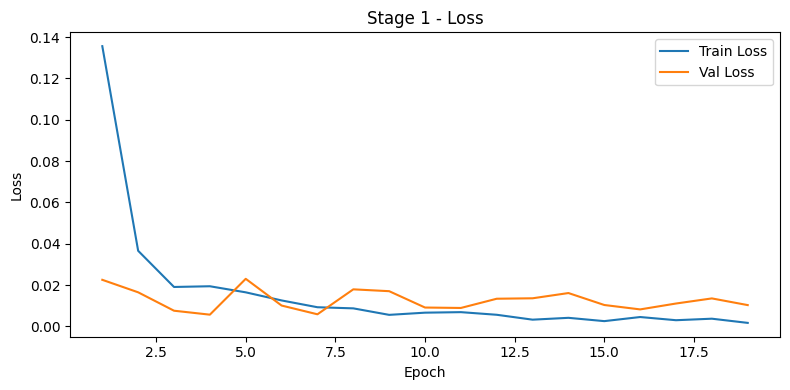

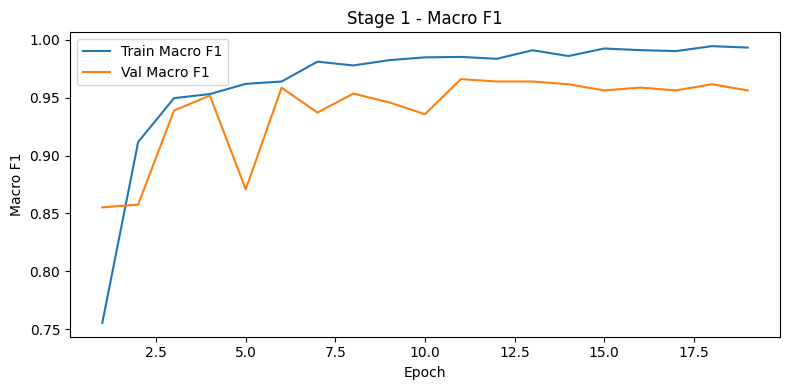

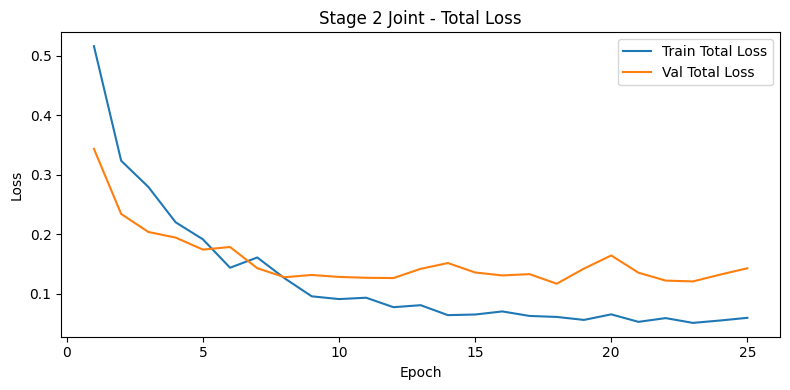

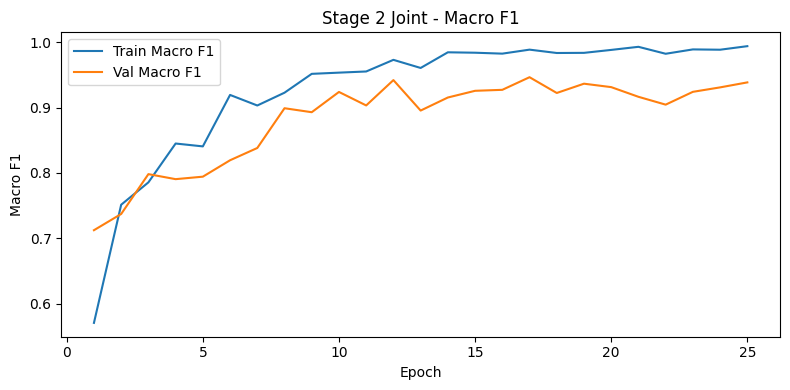

In [14]:

# Stage 1
epochs1 = range(1, len(history_stage1["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs1, history_stage1["train_loss"], label="Train Loss")
plt.plot(epochs1, history_stage1["val_loss"], label="Val Loss")
plt.title("Stage 1 - Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage1_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs1, history_stage1["train_macro_f1"], label="Train Macro F1")
plt.plot(epochs1, history_stage1["val_macro_f1"], label="Val Macro F1")
plt.title("Stage 1 - Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage1_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()

# Stage 2 joint
epochs2 = range(1, len(history_stage2_joint["train_loss"]) + 1)

plt.figure(figsize=(8, 4))
plt.plot(epochs2, history_stage2_joint["train_loss"], label="Train Total Loss")
plt.plot(epochs2, history_stage2_joint["val_loss"], label="Val Total Loss")
plt.title("Stage 2 Joint - Total Loss")
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_joint_total_loss.png", dpi=300, bbox_inches="tight")
plt.show()

plt.figure(figsize=(8, 4))
plt.plot(epochs2, history_stage2_joint["train_macro_f1"], label="Train Macro F1")
plt.plot(epochs2, history_stage2_joint["val_macro_f1"], label="Val Macro F1")
plt.title("Stage 2 Joint - Macro F1")
plt.xlabel("Epoch")
plt.ylabel("Macro F1")
plt.legend()
plt.tight_layout()
plt.savefig(FIG_DIR / "stage2_joint_macro_f1.png", dpi=300, bbox_inches="tight")
plt.show()


### Bước 15. Suy luận phân cấp 2-stage và xây dựng xác suất cuối cùng 6 lớp

In [15]:

# Stage 1 on all val/test
_, val_pred_stage1, val_prob_stage1 = predict_proba_stage1(stage1_model, val_loader_stage1, DEVICE)
_, test_pred_stage1, test_prob_stage1 = predict_proba_stage1(stage1_model, test_loader_stage1, DEVICE)

stage1_pred_labels_val = label_encoder_stage1.inverse_transform(val_pred_stage1)
stage1_pred_labels_test = label_encoder_stage1.inverse_transform(test_pred_stage1)

# Stage 2 on all val/test
X_val_all_stage2_scaled = scaler_stage2.transform(X_val)
X_val_all_stage2_fs = selector_stage2.transform(X_val_all_stage2_scaled)

X_test_all_stage2_scaled = scaler_stage2.transform(X_test)
X_test_all_stage2_fs = selector_stage2.transform(X_test_all_stage2_scaled)

val_stage2_all_ds = GeneDataset(X_val_all_stage2_fs, np.zeros(len(X_val_all_stage2_fs), dtype=int))
test_stage2_all_ds = GeneDataset(X_test_all_stage2_fs, np.zeros(len(X_test_all_stage2_fs), dtype=int))

val_stage2_all_loader = DataLoader(val_stage2_all_ds, batch_size=STAGE2_BATCH_SIZE, shuffle=False)
test_stage2_all_loader = DataLoader(test_stage2_all_ds, batch_size=STAGE2_BATCH_SIZE, shuffle=False)

_, val_pred_stage2_all, val_prob_stage2_all = predict_proba_stage2_joint(stage2_joint_model, val_stage2_all_loader, DEVICE)
_, test_pred_stage2_all, test_prob_stage2_all = predict_proba_stage2_joint(stage2_joint_model, test_stage2_all_loader, DEVICE)

stage2_pred_labels_val_all = label_encoder_stage2.inverse_transform(val_pred_stage2_all)
stage2_pred_labels_test_all = label_encoder_stage2.inverse_transform(test_pred_stage2_all)

# Hard predictions
final_val_pred_labels = stage1_pred_labels_val.copy()
final_test_pred_labels = stage1_pred_labels_test.copy()

val_pred_myeloid_idx = np.where(stage1_pred_labels_val == "Myeloid")[0]
test_pred_myeloid_idx = np.where(stage1_pred_labels_test == "Myeloid")[0]

final_val_pred_labels[val_pred_myeloid_idx] = stage2_pred_labels_val_all[val_pred_myeloid_idx]
final_test_pred_labels[test_pred_myeloid_idx] = stage2_pred_labels_test_all[test_pred_myeloid_idx]

final_val_pred = label_encoder_6class.transform(final_val_pred_labels)
final_test_pred = label_encoder_6class.transform(final_test_pred_labels)

# Final probabilities
stage1_idx = {name: i for i, name in enumerate(class_names_stage1)}
stage2_idx = {name: i for i, name in enumerate(class_names_stage2)}
final_idx = {name: i for i, name in enumerate(class_names_6class)}

final_val_prob = np.zeros((len(X_val), len(class_names_6class)))
final_test_prob = np.zeros((len(X_test), len(class_names_6class)))

final_val_prob[:, final_idx["ALL"]] = val_prob_stage1[:, stage1_idx["ALL"]]
final_val_prob[:, final_idx["CLL"]] = val_prob_stage1[:, stage1_idx["CLL"]]
final_val_prob[:, final_idx["Healthy"]] = val_prob_stage1[:, stage1_idx["Healthy"]]
final_val_prob[:, final_idx["AML"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["AML"]]
final_val_prob[:, final_idx["CML"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["CML"]]
final_val_prob[:, final_idx["MDS"]] = val_prob_stage1[:, stage1_idx["Myeloid"]] * val_prob_stage2_all[:, stage2_idx["MDS"]]

final_test_prob[:, final_idx["ALL"]] = test_prob_stage1[:, stage1_idx["ALL"]]
final_test_prob[:, final_idx["CLL"]] = test_prob_stage1[:, stage1_idx["CLL"]]
final_test_prob[:, final_idx["Healthy"]] = test_prob_stage1[:, stage1_idx["Healthy"]]
final_test_prob[:, final_idx["AML"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["AML"]]
final_test_prob[:, final_idx["CML"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["CML"]]
final_test_prob[:, final_idx["MDS"]] = test_prob_stage1[:, stage1_idx["Myeloid"]] * test_prob_stage2_all[:, stage2_idx["MDS"]]

print("Đã suy luận xong pipeline 2-stage.")
print("Validation predicted as Myeloid:", len(val_pred_myeloid_idx))
print("Test predicted as Myeloid:", len(test_pred_myeloid_idx))


Đã suy luận xong pipeline 2-stage.
Validation predicted as Myeloid: 181
Test predicted as Myeloid: 180


### Bước 16. Đánh giá cuối cùng trên bài toán 6 lớp

In [16]:

def evaluate_final_predictions(y_true, y_pred, y_prob, class_names, split_name):
    acc = accuracy_score(y_true, y_pred)
    macro_precision = precision_score(y_true, y_pred, average="macro", zero_division=0)
    macro_recall = recall_score(y_true, y_pred, average="macro", zero_division=0)
    macro_f1 = f1_score(y_true, y_pred, average="macro", zero_division=0)

    y_bin = label_binarize(y_true, classes=np.arange(len(class_names)))
    auc_macro_ovr = roc_auc_score(y_bin, y_prob, average="macro", multi_class="ovr")

    summary = pd.DataFrame([{
        "split": split_name,
        "accuracy": acc,
        "macro_precision": macro_precision,
        "macro_recall": macro_recall,
        "macro_f1": macro_f1,
        "auc_macro_ovr": auc_macro_ovr
    }])

    report_df = pd.DataFrame(
        classification_report(
            y_true, y_pred,
            target_names=class_names,
            output_dict=True,
            zero_division=0
        )
    ).transpose()

    return summary, report_df

val_summary, val_report = evaluate_final_predictions(
    y_val_6class, final_val_pred, final_val_prob, class_names_6class, "validation"
)
test_summary, test_report = evaluate_final_predictions(
    y_test_6class, final_test_pred, final_test_prob, class_names_6class, "test"
)

summary_df = pd.concat([val_summary, test_summary], ignore_index=True)
display(summary_df)

summary_df.to_csv(METRIC_DIR / "summary_metrics.csv", index=False)
val_report.to_csv(METRIC_DIR / "classification_report_validation.csv")
test_report.to_csv(METRIC_DIR / "classification_report_test.csv")


,split,accuracy,macro_precision,macro_recall,macro_f1,auc_macro_ovr
0,validation,0.970899,0.942916,0.955698,0.946257,0.997606
1,test,0.947230,0.907176,0.924819,0.913853,0.994791


### Bước 17. Vẽ confusion matrix cuối cùng trên tập test

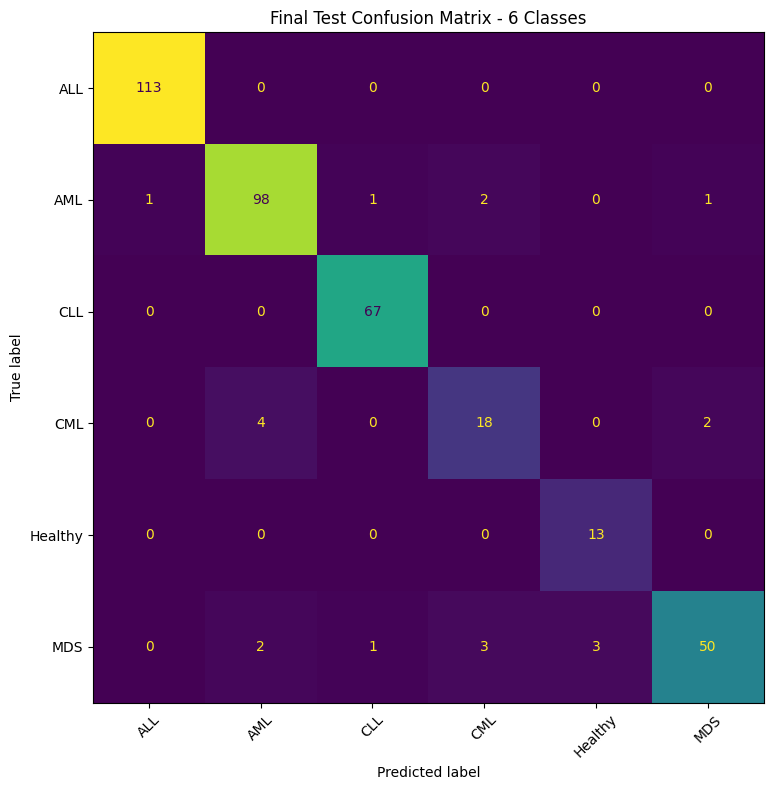

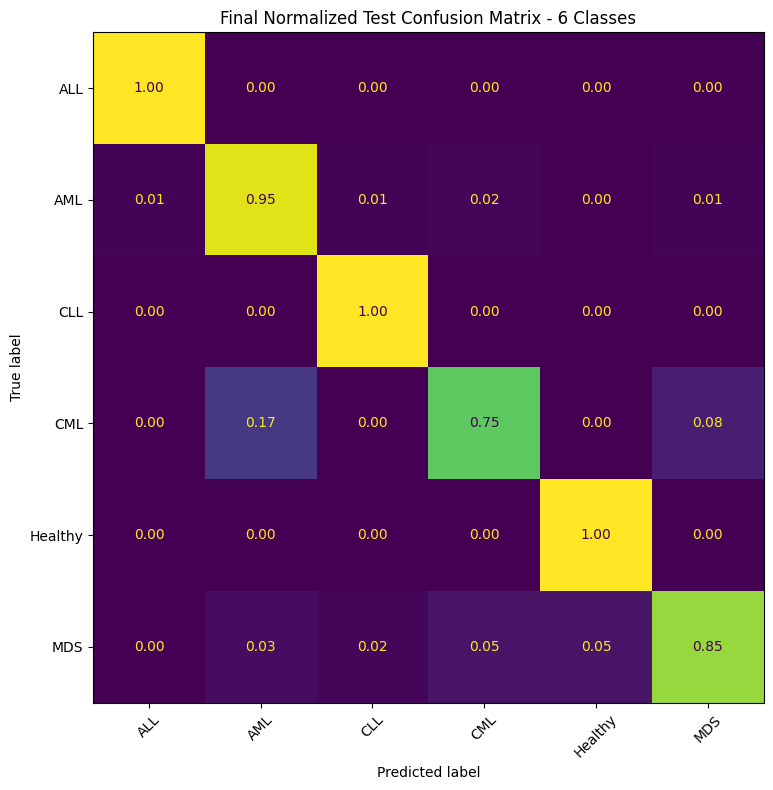

In [17]:

cm = confusion_matrix(y_test_6class, final_test_pred)
pd.DataFrame(cm, index=class_names_6class, columns=class_names_6class).to_csv(
    METRIC_DIR / "final_test_confusion_matrix.csv"
)

fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm, display_labels=class_names_6class)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False)
plt.title("Final Test Confusion Matrix - 6 Classes")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()

cm_norm = confusion_matrix(y_test_6class, final_test_pred, normalize="true")
fig, ax = plt.subplots(figsize=(8, 8))
disp = ConfusionMatrixDisplay(confusion_matrix=cm_norm, display_labels=class_names_6class)
disp.plot(ax=ax, xticks_rotation=45, colorbar=False, values_format=".2f")
plt.title("Final Normalized Test Confusion Matrix - 6 Classes")
plt.tight_layout()
plt.savefig(FIG_DIR / "final_normalized_test_confusion_matrix.png", dpi=300, bbox_inches="tight")
plt.show()


## Bước 18. Lưu object cần thiết và nhận xét sơ bộ

In [18]:

joblib.dump(label_encoder_6class, MODEL_DIR / "label_encoder_6class.pkl")

joblib.dump(label_encoder_stage1, MODEL_DIR / "label_encoder_stage1.pkl")
joblib.dump(scaler_stage1, MODEL_DIR / "scaler_stage1.pkl")
joblib.dump(selector_stage1, MODEL_DIR / "selector_stage1.pkl")

joblib.dump(label_encoder_stage2, MODEL_DIR / "label_encoder_stage2.pkl")
joblib.dump(scaler_stage2, MODEL_DIR / "scaler_stage2.pkl")
joblib.dump(selector_stage2, MODEL_DIR / "selector_stage2.pkl")

test_row = summary_df[summary_df["split"] == "test"].iloc[0]

print("=" * 82)
print("NHẬN XÉT SƠ BỘ - HIERARCHICAL TWO-STAGE JOINT AE-MLP")
print("=" * 82)
print(f"Accuracy test: {float(test_row['accuracy']):.4f}")
print(f"Macro Precision test: {float(test_row['macro_precision']):.4f}")
print(f"Macro Recall test: {float(test_row['macro_recall']):.4f}")
print(f"Macro F1 test: {float(test_row['macro_f1']):.4f}")
print(f"AUC macro OVR test: {float(test_row['auc_macro_ovr']):.4f}")
print("- ex04 pretrain Autoencoder trước, rồi fine-tune encoder + decoder + classifier cùng lúc.")
print("- Nếu ex04 vượt ex03, điều đó cho thấy latent representation có ích hơn sau khi fine-tune bằng supervised objective.")
print("- Nếu ex04 không vượt, thì ex03 vẫn là lựa chọn an toàn hơn cho báo cáo.")


NHẬN XÉT SƠ BỘ - HIERARCHICAL TWO-STAGE JOINT AE-MLP
Accuracy test: 0.9472
Macro Precision test: 0.9072
Macro Recall test: 0.9248
Macro F1 test: 0.9139
AUC macro OVR test: 0.9948
- ex04 pretrain Autoencoder trước, rồi fine-tune encoder + decoder + classifier cùng lúc.
- Nếu ex04 vượt ex03, điều đó cho thấy latent representation có ích hơn sau khi fine-tune bằng supervised objective.
- Nếu ex04 không vượt, thì ex03 vẫn là lựa chọn an toàn hơn cho báo cáo.
